# Virtualizing x86 debug registers under Rosetta

**This is an ongoing systems investigation into x86 debug-register virtualization across Wine and Rosetta.** Shadow register state and experimental execution-breakpoint delivery are implemented; full virtualization remains unfinished, including data watchpoints and general single-step correctness.

The motivating integration case was pretty simple: BO2 Zombies would start loading, then sit there burning CPU. The goal was to get past that hang without patching the game itself.

One integration milestone: a map loaded, and I could move around and play. That result does not establish complete debug-register virtualization. In between, the work came down to a surprisingly small distinction: **remembering a breakpoint is not the same as making it happen.**

Let's walk through that distinction before looking at any register names. The pictures are simplified explanations; the green test results come from the saved measurements.

You can read this notebook without running anything. Running its Python cells only reads the public test results and draws pictures. It does not launch the game.


## The clue: “sure, I set that”

The game got stuck at `Loading fastfile code_pre_gfx_zm`. Wine also logged that setting debug registers under Rosetta was unsupported and it was “faking success.”

That looked suspicious, but a suspicious log is not a diagnosis. So the investigation moved to tiny programs that had nothing to do with BO2.

Think of a breakpoint as a request: **“When execution reaches this instruction, stop and let my handler decide what happens next.”** A handler is just the program's code for responding to that stop. It can send execution somewhere else, remove the breakpoint, or carry on.

The first fix made Wine remember the request. If a program set a breakpoint and asked for it back, it got a consistent answer. That is useful—but the tiny test still ran right through the instruction without stopping.

So there were two jobs:

1. Remember what the program asked for.
2. Actually interrupt execution at the requested instruction.

The first Wine commit does job 1. The second does job 2. That's why they are separate commits.


In [1]:
import json, re
from pathlib import Path
from IPython.display import SVG, display

root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "test-results/validation-2026-10-08.json").is_file())
validation = json.loads((root / "test-results/validation-2026-10-08.json").read_text())
baseline = json.loads((root / "test-results/baseline-2026-10-08.json").read_text())
rows = [r for r in validation["matrix"]
        if re.search(r"matrix(?:32|64)\.exe$", r["args"][1])]
assert len(rows) == 24
assert all(r["exit"] == 0 for r in rows)
print(f"Execution-breakpoint matrix: {len(rows)}/24 passed")
for record in validation["upstream_isolated_tests"]:
    summary = re.search(r"\d+ tests executed.*?\d+ skipped\.", record["output"])
    print(record["arch"], "exit", record["exit"], "—", summary.group(0))


Execution-breakpoint matrix: 24/24 passed
i386 exit 0 — 126 tests executed (0 marked as todo, 0 as flaky, 0 failures), 0 skipped.
x86_64 exit 0 — 155 tests executed (0 marked as todo, 0 as flaky, 0 failures), 0 skipped.


## Follow the instruction pointer

A program runs instructions one after another. The **instruction pointer**, abbreviated PC here, says which instruction is next. Its actual register name is EIP in 32-bit code and RIP in 64-bit code.

A debug register called **DR0** can hold the instruction address we want to stop at. Another, **DR7**, says whether that breakpoint is enabled.

The question is then easy to picture: *is the next instruction the one we marked?*

On this Rosetta path, Wine wasn't installing a working physical hardware breakpoint. The opt-in implementation instead takes small internal steps and checks where execution has arrived. When it reaches an enabled target, it uses Wine's existing exception dispatch to let the program respond.

That internal stepping must stay invisible to the program. Otherwise one requested breakpoint would turn into a stream of unrelated stops. The **TF** flag is the single-step switch; Wine keeps its internal use separate from a program deliberately asking to step.

There's also a “let me get past this instruction once” flag, **RF**. Without preserving that through a 32-bit/64-bit transition, carrying on at the same address can trigger the same breakpoint again and again.

### Where the little bit of math comes in

For one enabled execution breakpoint, the basic match is simply

$$PC = DR0.$$

If two slots mark that same instruction, the program needs to hear about both. **DR6** is the hit report: slot 0 contributes 1, slot 1 contributes 2, so both together give

$$1 + 2 = 3.$$

The implementation also checks the enable bits, breakpoint type and RF suppression. Those details keep the simple picture honest.


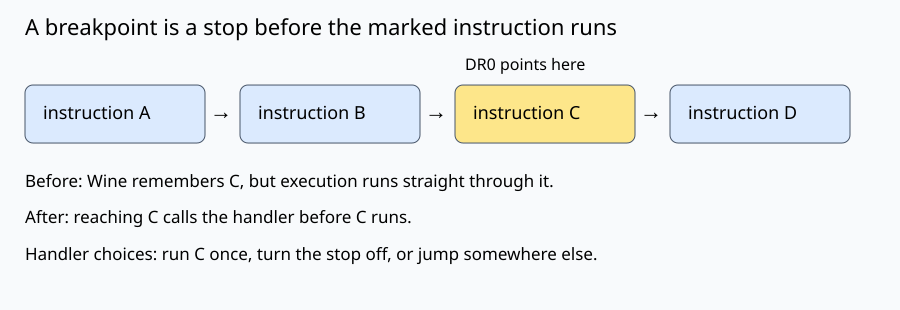

In [2]:
svg = '<svg xmlns="http://www.w3.org/2000/svg" width="900" height="310" viewBox="0 0 900 310"><rect width="900" height="310" fill="#f8fafc"/>'
svg += '<text x="25" y="35" font-family="sans-serif" font-size="22">A breakpoint is a stop before the marked instruction runs</text>'
for i, label in enumerate(["instruction A", "instruction B", "instruction C", "instruction D"]):
    x = 25 + i * 215
    color = "#fde68a" if i == 2 else "#dbeafe"
    svg += f'<rect x="{x}" y="85" width="180" height="58" rx="8" fill="{color}" stroke="#475569"/>'
    svg += f'<text x="{x+18}" y="119" font-family="sans-serif" font-size="18">{label}</text>'
    if i < 3: svg += f'<text x="{x+185}" y="119" font-size="22">→</text>'
svg += '<text x="465" y="70" font-family="sans-serif" font-size="16">DR0 points here</text>'
svg += '<text x="25" y="187" font-family="sans-serif" font-size="17">Before: Wine remembers C, but execution runs straight through it.</text>'
svg += '<text x="25" y="223" font-family="sans-serif" font-size="17">After: reaching C calls the handler before C runs.</text>'
svg += '<text x="25" y="260" font-family="sans-serif" font-size="17">Handler choices: run C once, turn the stop off, or jump somewhere else.</text></svg>'
display(SVG(svg))


## Okay, but does “continue” actually work?

Getting one stop is only half the job. What happens next matters just as much.

The tiny programs tried stopping at the first instruction, stopping after normal instructions, changing the next instruction, turning the breakpoint off, and continuing without changing anything. They also tried two slots at the same address and RF suppression.

Each green box below means that case returned the expected result and exited successfully. There are 12 cases for 32-bit/WOW64 and 12 for 64-bit code. **WOW64** is Wine's bridge for running a 32-bit Windows program inside its 64-bit environment.

Before delivery was implemented, the baseline reported zero execution hits. That couldn't tell us whether the handler worked—it never got called. These green results come from the fixed engine. We did not run a separate Windows reference machine in this session.


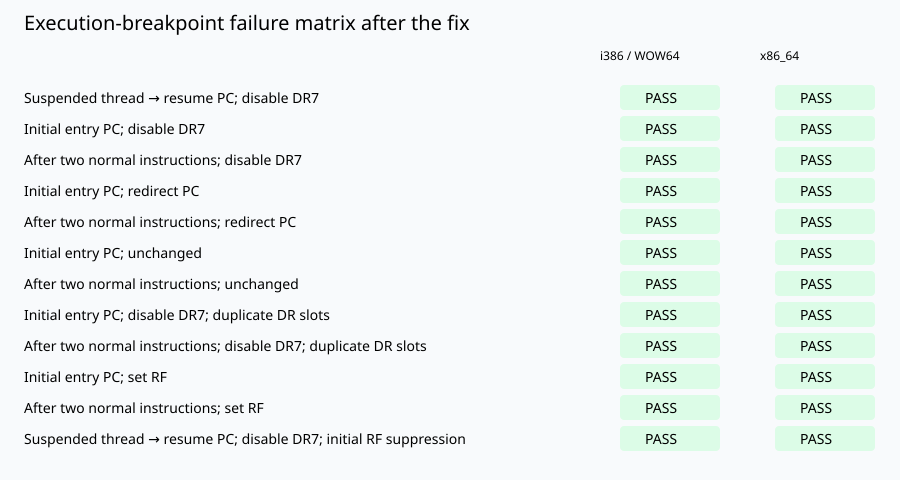

In [3]:
from html import escape
by_arch = {}
for r in rows:
    bits = re.search(r"matrix(32|64)\.exe$", r["args"][1]).group(1)
    by_arch.setdefault(bits, []).append(r)
assert all(len(by_arch[b]) == 12 for b in ["32", "64"])
locations = {"0": "After two normal instructions", "1": "Initial entry PC", "2": "Suspended thread → resume PC"}
actions = {"0": "disable DR7", "1": "redirect PC", "2": "unchanged", "3": "set RF"}
svg = '<svg xmlns="http://www.w3.org/2000/svg" width="900" height="480" viewBox="0 0 900 480"><rect width="900" height="480" fill="#f8fafc"/>'
svg += '<text x="24" y="30" font-family="sans-serif" font-size="20">Execution-breakpoint failure matrix after the fix</text>'
svg += '<text x="600" y="60" font-family="sans-serif">i386 / WOW64</text><text x="760" y="60" font-family="sans-serif">x86_64</text>'
for i, record in enumerate(by_arch["32"]):
    loc, action, duplicate, rf = record["args"][2:]
    label = locations[loc] + "; " + actions[action]
    if duplicate == "1": label += "; duplicate DR slots"
    if rf == "1": label += "; initial RF suppression"
    y = 85 + i * 31
    svg += f'<text x="24" y="{y+18}" font-family="sans-serif" font-size="14">{escape(label)}</text>'
    for bits, x in [("32", 620), ("64", 775)]:
        assert by_arch[bits][i]["args"][2:] == record["args"][2:]
        passed = by_arch[bits][i]["exit"] == 0
        color = "#dcfce7" if passed else "#fee2e2"
        svg += f'<rect x="{x}" y="{y}" width="100" height="25" rx="4" fill="{color}"/>'
        svg += f'<text x="{x+25}" y="{y+18}" font-family="sans-serif" font-size="14">{"PASS" if passed else "FAIL"}</text>'
svg += '</svg>'
display(SVG(svg))


## The side quest: CALL put the stack in the wrong place

A **CALL** jumps into another function. Before jumping, it leaves a return address on the stack: a bookmark saying where to come back. **RET** uses that bookmark.

In 32-bit code, that bookmark normally takes four bytes. So a CALL moves the stack pointer down by 4; RET brings it back by 4. The pair should leave no drift.

The TF-on case did something strange: CALL moved down **8** bytes, but RET came back only **4**. The stack ended up four bytes lower than it started.

| 32-bit case | Before CALL | At the called function | After RET |
|---|---|---|---|
| Normal execution | `0036fbcc` | `0036fbc8` | `0036fbcc` |
| Single-step enabled | `0036fbcc` | `0036fbc4` | `0036fbc8` |

Let's measure that instead of just calling it “weird”:

$$\text{CALL decrement} = ESP_{before} - ESP_{callee}$$

$$\text{drift} = ESP_{after\ RET} - ESP_{before}.$$

Normal execution gives a decrement of 4 and drift of 0. The affected stepped execution gives a decrement of 8 and drift of −4.

A raw macOS trap-context check saw the same stack pointer before Wine's regular handler processed it. That supports an actual change in stack state, rather than Wine merely printing the wrong number. It doesn't tell us exactly what Rosetta does internally.

Why not just add 4 to ESP? Because the return bookmark is at the old location. The workaround checks the exact direct CALL and its destination, validates the stack and return-address words, moves the return DWORD up four bytes, and only then adjusts ESP.

**The scope matters:** this separately enabled workaround covers internal breakpoint stepping. Ordinary application-requested TF stepping still shows the CALL bug. The internal CALL probe below passes; that is not a claim that every stepping case is fixed.


bits=64 before=000000000031F990 callee=000000000031F988 after=000000000031F990 actual_delta=8 expected=8
bits=32 before=0032FBF4 callee=0032FBF0 after=0032FBF4 actual_delta=4 expected=4


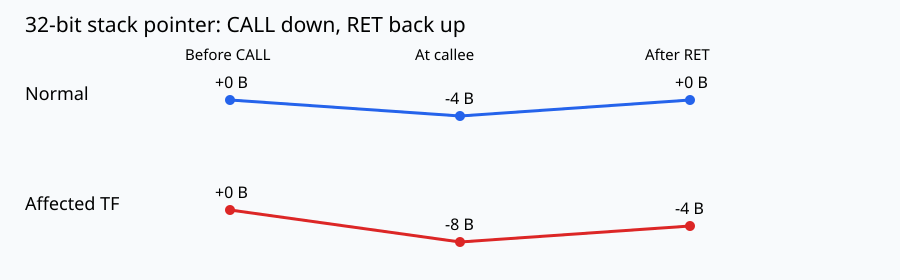

In [4]:
svg = '<svg xmlns="http://www.w3.org/2000/svg" width="900" height="280" viewBox="0 0 900 280"><rect width="900" height="280" fill="#f8fafc"/>'
svg += '<text x="25" y="32" font-family="sans-serif" font-size="21">32-bit stack pointer: CALL down, RET back up</text>'
for y, label, values, color in [(100, "Normal", [0, -4, 0], "#2563eb"), (210, "Affected TF", [0, -8, -4], "#dc2626")]:
    svg += f'<text x="25" y="{y}" font-family="sans-serif" font-size="18">{label}</text>'
    points = " ".join(f"{230+i*230},{y-value*4}" for i,value in enumerate(values))
    svg += f'<polyline points="{points}" fill="none" stroke="{color}" stroke-width="3"/>'
    for i, value in enumerate(values):
        x = 230+i*230; py=y-value*4
        svg += f'<circle cx="{x}" cy="{py}" r="5" fill="{color}"/><text x="{x-15}" y="{py-12}" font-family="sans-serif" font-size="16">{value:+d} B</text>'
for i,label in enumerate(["Before CALL", "At callee", "After RET"]):
    svg += f'<text x="{185+i*230}" y="60" font-family="sans-serif" font-size="15">{label}</text>'
svg += '</svg>'
display(SVG(svg))

call_rows = [r for r in validation["matrix"] if "internal-call" in r["args"][1]]
assert len(call_rows) == 2
for record in call_rows:
    assert record["exit"] == 0
    print(record["output"].strip())


## Back to Zombies

The generic tests gave us a reason to try the game again. With the patched WineCX engine, Zombies got beyond the original loading hang, loaded a map, and allowed movement/play.

That's the result this project celebrates. It wasn't a long-session benchmark, and controller support wasn't established. The installed Whisky runtime and original game bottle were left alone. No game-specific address or executable patch was added to Wine.

## Why are there two patch targets?

There is **one behavior we're trying to implement:** the Windows program sets an execution breakpoint, gets the right stop, and can continue correctly.

There are **two source versions** involved:

- **Upstream Wine:** the two consecutive commits intended for upstream review.
- **WineCX:** the Wine variant used by the working BO2 runtime. The same behavior is adapted to its surrounding code.

Think of it as the same change applied to two editions of a book: the paragraphs around it aren't identical, so the edit needs different context. It isn't a different set of game rules.

This public repo is the walkthrough, probes, results and patch exports. The Wine fork contains the actual contribution commits. A WineCX submission would be optional and separate. These commits are local; this notebook does not claim they have already been accepted upstream.

## Where to look next

| File or commit | What it gives you |
|---|---|
| Wine `b81e0922706` | Remember the requested debug-register state |
| Wine `6901e703d31` | Deliver execution stops, test continuation, gate the CALL workaround |
| `patches/` | Exports of the two upstream commits |
| `bo2/patches/` | Compatibility versions for the tested WineCX source |
| `probes/` | Small programs that reproduce the behavior without BO2 |
| `test-results/` | The raw measurements behind the pictures |

The next upstream work is review, broader signal-safety and performance assessment, and deciding how to handle the remaining ordinary TF/CALL anomaly. The playable result is real; upstream acceptance is still a separate milestone.
